In [1]:
import pandas as pd
import numpy as np

# Load normalized JobMatch dataset
job_df = pd.read_csv("../data/processed/job_dataset_normalized.csv")

print("JOBMATCH DATASET LOADED SUCCESSFULLY")
print("=" * 60)

print("Dataset shape:", job_df.shape)

print("\nColumn names:")
for column in job_df.columns:
    print("-", column)

print("\nFirst five records:")
display(job_df.head())

print("\nData types:")
display(job_df.dtypes.to_frame(name="Data Type"))

JOBMATCH DATASET LOADED SUCCESSFULLY
Dataset shape: (6000, 16)

Column names:
- Highest_Qualification
- Specialization
- Experience_Years
- Technical_Skills
- Soft_Skills
- Certifications
- Fields_of_Interest
- Employment_Type_Interest
- Expected_Salary_INR_Annual
- Resume_Summary
- Recommended_Job
- Salary_At_Observed_Cap
- Technical_Skills_Parsed
- Soft_Skills_Parsed
- Technical_Skill_Count
- Soft_Skill_Count

First five records:


,Highest_Qualification,Specialization,Experience_Years,Technical_Skills,Soft_Skills,Certifications,Fields_of_Interest,Employment_Type_Interest,Expected_Salary_INR_Annual,Resume_Summary,Recommended_Job,Salary_At_Observed_Cap,Technical_Skills_Parsed,Soft_Skills_Parsed,Technical_Skill_Count,Soft_Skill_Count
0,BCA,Business Administration,10,Talent Acquisition; HRIS; Excel; Communication...,Creativity; Leadership; Decision Making; Time ...,Google Data Analytics,Human Resources,Contract,500000,Candidate with 10 years of experience interest...,HR Manager / Talent Acquisition Lead,True,Talent Acquisition; HRIS; Excel; Communication...,Creativity; Leadership; Decision Making; Time ...,5,4
1,B.Com,Information Technology,0,Python; Power BI; Tableau; NumPy,Problem Solving; Teamwork; Adaptability; Colla...,Azure Fundamentals,Data Analytics,Freelance,358000,Entry-level candidate interested in Data Analy...,Junior Data Analyst,False,Python; Power BI; Tableau; NumPy,Problem Solving; Teamwork; Adaptability; Colla...,4,4
2,B.Sc,Information Technology,0,Selenium; Jira; Manual Testing; SQL; Python,Critical Thinking; Adaptability,Microsoft Power BI Data Analyst,Quality Assurance,Part-time,302000,Entry-level candidate interested in Quality As...,Junior QA / Test Engineer,False,Selenium; Jira; Manual Testing; SQL; Python,Critical Thinking; Adaptability,5,2
3,B.Sc,Cloud Computing,1,Power BI; Process Mapping; Documentation; Exce...,Problem Solving; Creativity,Google UX Design,Business Analysis,Internship,375000,Candidate with 1 years of experience intereste...,Junior Business Analyst,False,Power BI; Process Mapping; Documentation; Exce...,Problem Solving; Creativity,5,2
4,B.Com,Statistics,0,CI/CD; Kubernetes; Git; AWS,Critical Thinking; Collaboration,Digital Marketing Certificate,Cloud Computing,Full-time,268000,Entry-level candidate interested in Cloud Comp...,Junior Cloud Engineer,False,CI/CD; Kubernetes; Git; AWS,Critical Thinking; Collaboration,4,2



Data types:


,Data Type
Highest_Qualification,str
Specialization,str
Experience_Years,int64
Technical_Skills,str
Soft_Skills,str
Certifications,str
Fields_of_Interest,str
Employment_Type_Interest,str
Expected_Salary_INR_Annual,int64
Resume_Summary,str


In [2]:
# Define target variable
target = "Recommended_Job"

# Features without Experience and Fields of Interest
features_without_exp_interest = [
    "Highest_Qualification",
    "Specialization",
    "Technical_Skills_Parsed",
    "Soft_Skills_Parsed",
    "Certifications",
    "Employment_Type_Interest",
    "Technical_Skill_Count",
    "Soft_Skill_Count"
]

# Features with Experience, without Fields of Interest
features_with_exp = features_without_exp_interest + [
    "Experience_Years"
]

# Features with Fields of Interest, without Experience
features_with_interest = features_without_exp_interest + [
    "Fields_of_Interest"
]

# Features with both Experience and Fields of Interest
features_with_both = features_with_exp + [
    "Fields_of_Interest"
]

print("TARGET:", target)
print("\nNumber of target classes:", job_df[target].nunique())

print("\nFeature experiment configurations:")
print("1. Without Experience and Fields of Interest:",
      len(features_without_exp_interest))
print("2. With Experience:",
      len(features_with_exp))
print("3. With Fields of Interest:",
      len(features_with_interest))
print("4. With both:",
      len(features_with_both))

print("\nTarget distribution:")
display(job_df[target].value_counts().to_frame("Record_Count"))

TARGET: Recommended_Job

Number of target classes: 34

Feature experiment configurations:
1. Without Experience and Fields of Interest: 8
2. With Experience: 9
3. With Fields of Interest: 9
4. With both: 10

Target distribution:


,Record_Count
Recommended_Job,
Web Developer,510
Junior Financial Analyst,260
Digital Marketing Associate,260
Junior QA / Test Engineer,255
Junior Machine Learning Associate,246
HR / Recruitment Associate,246
Junior Business Analyst,245
Junior Data Analyst,243
Junior UI/UX Designer,239


In [3]:
# Validate all selected features

all_features = list(dict.fromkeys(
    features_without_exp_interest
    + features_with_exp
    + features_with_interest
    + features_with_both
))

print("FEATURE VALIDATION")
print("=" * 60)

print("Total unique candidate features:", len(all_features))

print("\nMissing values:")
display(job_df[all_features + [target]].isnull().sum().to_frame(
    name="Missing_Count"
))

print("\nEmpty string counts:")
empty_counts = {}

for column in all_features + [target]:
    if job_df[column].dtype == "object":
        empty_counts[column] = (
            job_df[column].astype(str).str.strip().eq("").sum()
        )

display(pd.Series(empty_counts, name="Empty_Count").to_frame())

print("\nValidation complete.")

FEATURE VALIDATION
Total unique candidate features: 10

Missing values:


,Missing_Count
Highest_Qualification,0
Specialization,0
Technical_Skills_Parsed,0
Soft_Skills_Parsed,0
Certifications,0
Employment_Type_Interest,0
Technical_Skill_Count,0
Soft_Skill_Count,0
Experience_Years,0
Fields_of_Interest,0



Empty string counts:


,Empty_Count



Validation complete.


In [4]:
from sklearn.model_selection import train_test_split

# Separate target
y = job_df[target]

# Create a common train-test split
train_indices, test_indices = train_test_split(
    job_df.index,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Training and testing targets
y_train = job_df.loc[train_indices, target]
y_test = job_df.loc[test_indices, target]

print("DATA SPLITTING COMPLETED")
print("=" * 60)

print("Total records:", len(job_df))
print("Training records:", len(train_indices))
print("Testing records:", len(test_indices))

print("\nTraining target classes:", y_train.nunique())
print("Testing target classes:", y_test.nunique())

print("\nTraining distribution:")
display(y_train.value_counts().sort_index().to_frame("Train_Count"))

print("\nTesting distribution:")
display(y_test.value_counts().sort_index().to_frame("Test_Count"))

DATA SPLITTING COMPLETED
Total records: 6000
Training records: 4800
Testing records: 1200

Training target classes: 34
Testing target classes: 34

Training distribution:


,Train_Count
Recommended_Job,
Business Analyst,138
Cloud Engineer,160
Cybersecurity Analyst,132
Data Analyst,152
Digital Marketing Associate,208
Digital Marketing Manager,61
Digital Marketing Specialist,140
Financial Analyst,125
HR / Recruitment Associate,197



Testing distribution:


,Test_Count
Recommended_Job,
Business Analyst,34
Cloud Engineer,40
Cybersecurity Analyst,33
Data Analyst,38
Digital Marketing Associate,52
Digital Marketing Manager,15
Digital Marketing Specialist,35
Financial Analyst,31
HR / Recruitment Associate,49


In [5]:
# Create feature datasets for four experiments

X_train_without_exp_interest = job_df.loc[
    train_indices, features_without_exp_interest
].copy()

X_test_without_exp_interest = job_df.loc[
    test_indices, features_without_exp_interest
].copy()

X_train_with_exp = job_df.loc[
    train_indices, features_with_exp
].copy()

X_test_with_exp = job_df.loc[
    test_indices, features_with_exp
].copy()

X_train_with_interest = job_df.loc[
    train_indices, features_with_interest
].copy()

X_test_with_interest = job_df.loc[
    test_indices, features_with_interest
].copy()

X_train_with_both = job_df.loc[
    train_indices, features_with_both
].copy()

X_test_with_both = job_df.loc[
    test_indices, features_with_both
].copy()

print("FEATURE DATASETS CREATED")
print("=" * 60)

print("Without Experience and Interest:",
      X_train_without_exp_interest.shape,
      X_test_without_exp_interest.shape)

print("With Experience:",
      X_train_with_exp.shape,
      X_test_with_exp.shape)

print("With Fields of Interest:",
      X_train_with_interest.shape,
      X_test_with_interest.shape)

print("With Both:",
      X_train_with_both.shape,
      X_test_with_both.shape)

print("\nTarget shapes:", y_train.shape, y_test.shape)

FEATURE DATASETS CREATED
Without Experience and Interest: (4800, 8) (1200, 8)
With Experience: (4800, 9) (1200, 9)
With Fields of Interest: (4800, 9) (1200, 9)
With Both: (4800, 10) (1200, 10)

Target shapes: (4800,) (1200,)


In [7]:
# Create four preprocessing configurations

preprocessor_1 = create_preprocessor(
    include_experience=False,
    include_interest=False
)

preprocessor_2 = create_preprocessor(
    include_experience=True,
    include_interest=False
)

preprocessor_3 = create_preprocessor(
    include_experience=False,
    include_interest=True
)

preprocessor_4 = create_preprocessor(
    include_experience=True,
    include_interest=True
)

print("FOUR PREPROCESSORS CREATED SUCCESSFULLY")
print("=" * 60)

print("1. Baseline: No Experience, No Fields of Interest")
print("2. With Experience")
print("3. With Fields of Interest")
print("4. With Experience and Fields of Interest")

FOUR PREPROCESSORS CREATED SUCCESSFULLY
1. Baseline: No Experience, No Fields of Interest
2. With Experience
3. With Fields of Interest
4. With Experience and Fields of Interest


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

# Define feature groups
categorical_features = [
    "Highest_Qualification",
    "Specialization",
    "Certifications",
    "Employment_Type_Interest"
]

text_features = [
    "Technical_Skills_Parsed",
    "Soft_Skills_Parsed"
]

numeric_features = [
    "Technical_Skill_Count",
    "Soft_Skill_Count"
]

# Function to create preprocessing pipeline
def create_preprocessor(include_experience=False, include_interest=False):

    categorical_columns = categorical_features.copy()
    numeric_columns = numeric_features.copy()

    if include_experience:
        numeric_columns.append("Experience_Years")

    if include_interest:
        categorical_columns.append("Fields_of_Interest")

    transformers = [
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        ),
        (
            "technical_text",
            TfidfVectorizer(),
            "Technical_Skills_Parsed"
        ),
        (
            "soft_text",
            TfidfVectorizer(),
            "Soft_Skills_Parsed"
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_columns
        )
    ]

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )


print("PREPROCESSING FUNCTION CREATED")
print("Categorical features:", categorical_features)
print("Text features:", text_features)
print("Numeric features:", numeric_features)

PREPROCESSING FUNCTION CREATED
Categorical features: ['Highest_Qualification', 'Specialization', 'Certifications', 'Employment_Type_Interest']
Text features: ['Technical_Skills_Parsed', 'Soft_Skills_Parsed']
Numeric features: ['Technical_Skill_Count', 'Soft_Skill_Count']


In [8]:
# Fit preprocessing on training data only

X_train_processed_1 = preprocessor_1.fit_transform(
    X_train_without_exp_interest
)

# Transform testing data using the fitted preprocessor
X_test_processed_1 = preprocessor_1.transform(
    X_test_without_exp_interest
)

print("BASELINE PREPROCESSING COMPLETED")
print("=" * 60)

print("Training matrix shape:", X_train_processed_1.shape)
print("Testing matrix shape:", X_test_processed_1.shape)

print("\nTraining matrix type:", type(X_train_processed_1))
print("Testing matrix type:", type(X_test_processed_1))

print("\nTraining matrix contains NaN:",
      np.isnan(X_train_processed_1.data).any()
      if hasattr(X_train_processed_1, "data")
      else np.isnan(X_train_processed_1).any())

BASELINE PREPROCESSING COMPLETED
Training matrix shape: (4800, 146)
Testing matrix shape: (1200, 146)

Training matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Testing matrix type: <class 'scipy.sparse._csr.csr_matrix'>

Training matrix contains NaN: False


In [9]:
# Configuration 2: With Experience
X_train_processed_2 = preprocessor_2.fit_transform(X_train_with_exp)
X_test_processed_2 = preprocessor_2.transform(X_test_with_exp)

# Configuration 3: With Fields of Interest
X_train_processed_3 = preprocessor_3.fit_transform(X_train_with_interest)
X_test_processed_3 = preprocessor_3.transform(X_test_with_interest)

# Configuration 4: With Both
X_train_processed_4 = preprocessor_4.fit_transform(X_train_with_both)
X_test_processed_4 = preprocessor_4.transform(X_test_with_both)

print("ALL REMAINING CONFIGURATIONS TRANSFORMED")
print("=" * 60)

print("With Experience:")
print(X_train_processed_2.shape, X_test_processed_2.shape)

print("\nWith Fields of Interest:")
print(X_train_processed_3.shape, X_test_processed_3.shape)

print("\nWith Both:")
print(X_train_processed_4.shape, X_test_processed_4.shape)

ALL REMAINING CONFIGURATIONS TRANSFORMED
With Experience:
(4800, 147) (1200, 147)

With Fields of Interest:
(4800, 158) (1200, 158)

With Both:
(4800, 159) (1200, 159)


In [10]:
# Validate all transformed matrices

processed_datasets = {
    "Baseline": (X_train_processed_1, X_test_processed_1),
    "With Experience": (X_train_processed_2, X_test_processed_2),
    "With Fields of Interest": (X_train_processed_3, X_test_processed_3),
    "With Both": (X_train_processed_4, X_test_processed_4)
}

print("TRANSFORMED DATA VALIDATION")
print("=" * 65)

for name, (X_train, X_test) in processed_datasets.items():

    train_nan = np.isnan(X_train.data).any()
    test_nan = np.isnan(X_test.data).any()

    train_inf = np.isinf(X_train.data).any()
    test_inf = np.isinf(X_test.data).any()

    print(f"\n{name}")
    print("Training shape:", X_train.shape)
    print("Testing shape:", X_test.shape)
    print("Training NaN:", train_nan)
    print("Testing NaN:", test_nan)
    print("Training Infinite:", train_inf)
    print("Testing Infinite:", test_inf)

TRANSFORMED DATA VALIDATION

Baseline
Training shape: (4800, 146)
Testing shape: (1200, 146)
Training NaN: False
Testing NaN: False
Training Infinite: False
Testing Infinite: False

With Experience
Training shape: (4800, 147)
Testing shape: (1200, 147)
Training NaN: False
Testing NaN: False
Training Infinite: False
Testing Infinite: False

With Fields of Interest
Training shape: (4800, 158)
Testing shape: (1200, 158)
Training NaN: False
Testing NaN: False
Training Infinite: False
Testing Infinite: False

With Both
Training shape: (4800, 159)
Testing shape: (1200, 159)
Training NaN: False
Testing NaN: False
Training Infinite: False
Testing Infinite: False


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# Store trained models and results
logistic_models = {}
logistic_results = []

# Four configurations
experiments = {
    "Baseline": X_train_processed_1,
    "With Experience": X_train_processed_2,
    "With Fields of Interest": X_train_processed_3,
    "With Both": X_train_processed_4
}

test_experiments = {
    "Baseline": X_test_processed_1,
    "With Experience": X_test_processed_2,
    "With Fields of Interest": X_test_processed_3,
    "With Both": X_test_processed_4
}

# Train Logistic Regression
for name in experiments:

    print(f"\nTraining Logistic Regression: {name}")

    model = LogisticRegression(
        max_iter=2000,
        random_state=42
    )

    model.fit(experiments[name], y_train)

    predictions = model.predict(test_experiments[name])

    logistic_models[name] = model

    logistic_results.append({
        "Configuration": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced_Accuracy": balanced_accuracy_score(y_test, predictions),
        "Macro_F1": f1_score(y_test, predictions, average="macro"),
        "Weighted_F1": f1_score(y_test, predictions, average="weighted")
    })

print("\nALL LOGISTIC REGRESSION MODELS TRAINED")

logistic_results_df = pd.DataFrame(logistic_results)

display(
    logistic_results_df.round(4)
)


Training Logistic Regression: Baseline

Training Logistic Regression: With Experience

Training Logistic Regression: With Fields of Interest

Training Logistic Regression: With Both

ALL LOGISTIC REGRESSION MODELS TRAINED


,Configuration,Accuracy,Balanced_Accuracy,Macro_F1,Weighted_F1
0,Baseline,0.4875,0.3551,0.3410,0.4616
1,With Experience,0.9642,0.9323,0.9454,0.9630
2,With Fields of Interest,0.4875,0.3565,0.3445,0.4650
3,With Both,0.9725,0.9481,0.9577,0.9718


In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

random_forest_models = {}
random_forest_results = []

for name in experiments:

    print(f"\nTraining Random Forest: {name}")

    model = RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model.fit(experiments[name], y_train)

    predictions = model.predict(test_experiments[name])

    random_forest_models[name] = model

    random_forest_results.append({
        "Configuration": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced_Accuracy": balanced_accuracy_score(y_test, predictions),
        "Macro_F1": f1_score(y_test, predictions, average="macro"),
        "Weighted_F1": f1_score(y_test, predictions, average="weighted")
    })

print("\nALL RANDOM FOREST MODELS TRAINED")

random_forest_results_df = pd.DataFrame(random_forest_results)

display(random_forest_results_df.round(4))


Training Random Forest: Baseline

Training Random Forest: With Experience

Training Random Forest: With Fields of Interest

Training Random Forest: With Both

ALL RANDOM FOREST MODELS TRAINED


,Configuration,Accuracy,Balanced_Accuracy,Macro_F1,Weighted_F1
0,Baseline,0.4792,0.3593,0.3512,0.4650
1,With Experience,0.9925,0.9912,0.9915,0.9925
2,With Fields of Interest,0.4942,0.3709,0.3626,0.4799
3,With Both,0.9975,0.9932,0.9950,0.9974


In [16]:
# Feature importance analysis

best_rf_model = random_forest_models["With Both"]
best_preprocessor = preprocessor_4

feature_names = best_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("TOP 20 MOST IMPORTANT FEATURES")
print("=" * 60)

display(importance_df.head(20).round(5))


TOP 20 MOST IMPORTANT FEATURES


,Feature,Importance
0,numeric__Experience_Years,0.19750
1,categorical__Fields_of_Interest_Software Devel...,0.02496
2,categorical__Fields_of_Interest_Data Analytics,0.02460
3,categorical__Fields_of_Interest_Cloud Computing,0.02331
4,categorical__Fields_of_Interest_AI/ML,0.02284
5,categorical__Fields_of_Interest_Quality Assurance,0.01759
6,categorical__Fields_of_Interest_Web Development,0.01651
7,categorical__Fields_of_Interest_Finance,0.01594
8,categorical__Fields_of_Interest_Cybersecurity,0.01553
9,categorical__Fields_of_Interest_Business Analysis,0.01543


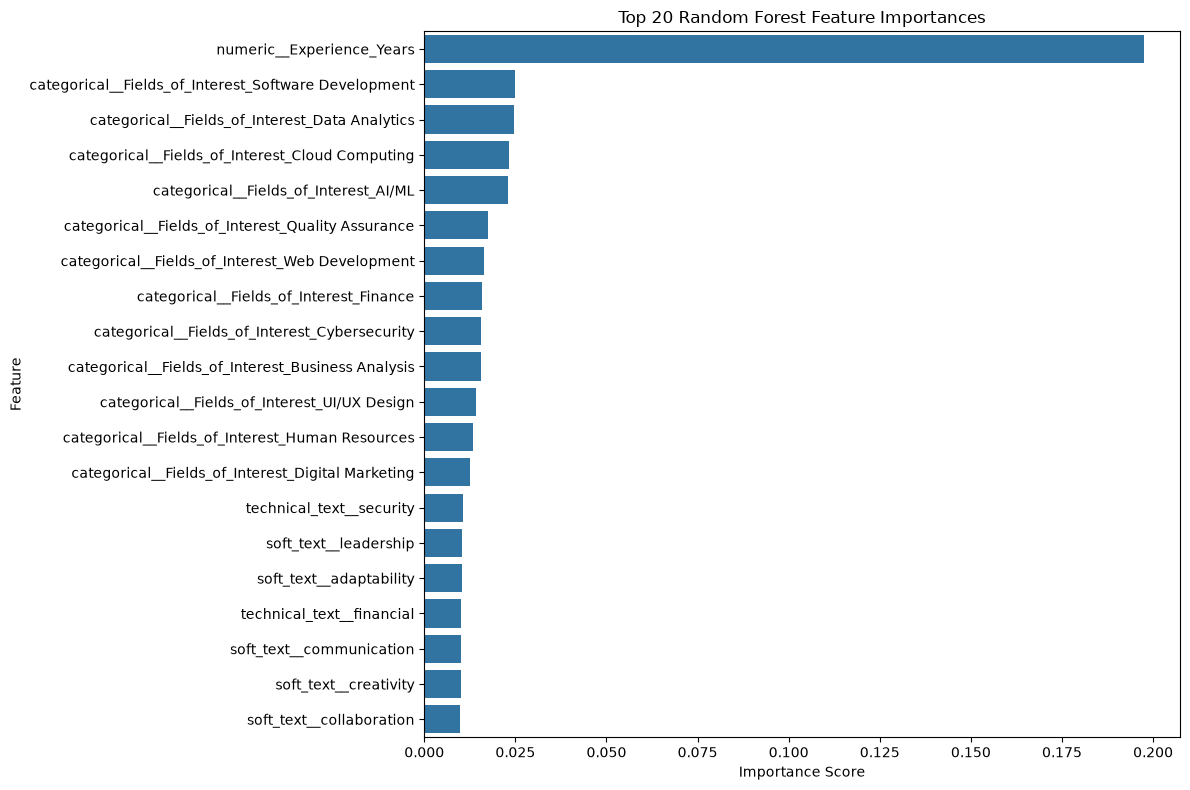

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.barplot(
    data=importance_df.head(20),
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Random Forest Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [17]:
from sklearn.metrics import classification_report, confusion_matrix

# Generate predictions
best_predictions = best_rf_model.predict(X_test_processed_4)

# Compare actual and predicted labels
prediction_comparison = pd.DataFrame({
    "Actual_Job": y_test.values,
    "Predicted_Job": best_predictions
})

prediction_comparison["Correct"] = (
    prediction_comparison["Actual_Job"] ==
    prediction_comparison["Predicted_Job"]
)

print("PREDICTION ANALYSIS")
print("=" * 60)

print("Correct predictions:",
      prediction_comparison["Correct"].sum())

print("Incorrect predictions:",
      (~prediction_comparison["Correct"]).sum())

print("\nClassification Report:")

print(classification_report(
    y_test,
    best_predictions,
    zero_division=0
))

print("\nIncorrect prediction examples:")

display(
    prediction_comparison[
        ~prediction_comparison["Correct"]
    ].head(20)
)

PREDICTION ANALYSIS
Correct predictions: 1197
Incorrect predictions: 3

Classification Report:
                                            precision    recall  f1-score   support

                          Business Analyst       1.00      1.00      1.00        34
                            Cloud Engineer       1.00      1.00      1.00        40
                     Cybersecurity Analyst       1.00      1.00      1.00        33
                              Data Analyst       1.00      1.00      1.00        38
               Digital Marketing Associate       1.00      1.00      1.00        52
                 Digital Marketing Manager       1.00      1.00      1.00        15
              Digital Marketing Specialist       1.00      1.00      1.00        35
                         Financial Analyst       1.00      1.00      1.00        31
                HR / Recruitment Associate       1.00      1.00      1.00        49
HR Analyst / Talent Acquisition Specialist       1.00      1.00 

,Actual_Job,Predicted_Job,Correct
259,Senior QA Engineer,QA / Software Test Engineer,False
270,Senior QA Engineer,QA / Software Test Engineer,False
865,Senior QA Engineer,QA / Software Test Engineer,False


In [18]:
# Inspect incorrect predictions with their input features

incorrect_indices = prediction_comparison[
    ~prediction_comparison["Correct"]
].index

incorrect_records = job_df.loc[
    test_indices[incorrect_indices]
].copy()

display(
    incorrect_records[
        [
            "Highest_Qualification",
            "Specialization",
            "Experience_Years",
            "Technical_Skills",
            "Soft_Skills",
            "Fields_of_Interest",
            "Recommended_Job"
        ]
    ]
)

,Highest_Qualification,Specialization,Experience_Years,Technical_Skills,Soft_Skills,Fields_of_Interest,Recommended_Job
4888,M.Sc,Statistics,7,Test Cases; Python; Manual Testing; Jira; SQL;...,Teamwork; Adaptability; Decision Making,Quality Assurance,Senior QA Engineer
1839,B.Com,Mechanical Engineering,6,API Testing; Manual Testing; Test Cases; Jira;...,Leadership; Problem Solving,Quality Assurance,Senior QA Engineer
1174,M.Tech,Data Science,7,Manual Testing; Test Cases; API Testing; Jira,Adaptability; Time Management; Collaboration,Quality Assurance,Senior QA Engineer


In [19]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Create complete preprocessing pipeline
cv_pipeline = Pipeline([
    ("preprocessor", create_preprocessor(
        include_experience=True,
        include_interest=True
    )),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    cv_pipeline,
    job_df[features_with_both],
    job_df[target],
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy",
        "macro_f1": "f1_macro"
    },
    n_jobs=-1
)

# Display results
cv_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Macro F1"
    ],
    "Mean": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_balanced_accuracy"].mean(),
        cv_results["test_macro_f1"].mean()
    ],
    "Standard Deviation": [
        cv_results["test_accuracy"].std(),
        cv_results["test_balanced_accuracy"].std(),
        cv_results["test_macro_f1"].std()
    ]
})

display(cv_summary.round(4))

,Metric,Mean,Standard Deviation
0,Accuracy,0.9963,0.0015
1,Balanced Accuracy,0.9924,0.0037
2,Macro F1,0.9944,0.0026


In [20]:
# Compare Logistic Regression and Random Forest

comparison_df = pd.DataFrame({
    "Configuration": [
        "Baseline",
        "With Experience",
        "With Fields of Interest",
        "With Both"
    ],
    "Logistic Regression Accuracy": [
        0.4875, 0.9642, 0.4875, 0.9725
    ],
    "Random Forest Accuracy": [
        0.4792, 0.9925, 0.4942, 0.9975
    ],
    "Logistic Regression Macro F1": [
        0.3410, 0.9454, 0.3445, 0.9577
    ],
    "Random Forest Macro F1": [
        0.3512, 0.9915, 0.3626, 0.9950
    ]
})

display(comparison_df.round(4))

,Configuration,Logistic Regression Accuracy,Random Forest Accuracy,Logistic Regression Macro F1,Random Forest Macro F1
0,Baseline,0.4875,0.4792,0.3410,0.3512
1,With Experience,0.9642,0.9925,0.9454,0.9915
2,With Fields of Interest,0.4875,0.4942,0.3445,0.3626
3,With Both,0.9725,0.9975,0.9577,0.9950


In [21]:
import joblib
from pathlib import Path

# Create model directory
model_dir = Path("../models/jobmatch")
model_dir.mkdir(parents=True, exist_ok=True)

# Save fitted preprocessor
joblib.dump(
    preprocessor_4,
    model_dir / "jobmatch_preprocessor.joblib"
)

# Save trained Random Forest model
joblib.dump(
    random_forest_models["With Both"],
    model_dir / "jobmatch_random_forest.joblib"
)

# Save feature configuration
joblib.dump(
    features_with_both,
    model_dir / "jobmatch_features.joblib"
)

print("JOBMATCH MODEL SAVED SUCCESSFULLY!")
print("=" * 50)

print("1. jobmatch_preprocessor.joblib")
print("2. jobmatch_random_forest.joblib")
print("3. jobmatch_features.joblib")

JOBMATCH MODEL SAVED SUCCESSFULLY!
1. jobmatch_preprocessor.joblib
2. jobmatch_random_forest.joblib
3. jobmatch_features.joblib


In [22]:
import joblib
from pathlib import Path

model_dir = Path("../models/jobmatch")

# Load saved files
loaded_preprocessor = joblib.load(
    model_dir / "jobmatch_preprocessor.joblib"
)

loaded_model = joblib.load(
    model_dir / "jobmatch_random_forest.joblib"
)

loaded_features = joblib.load(
    model_dir / "jobmatch_features.joblib"
)

print("SAVED MODEL VERIFICATION")
print("=" * 50)

print("Preprocessor loaded:", loaded_preprocessor is not None)
print("Random Forest loaded:", loaded_model is not None)
print("Number of features:", len(loaded_features))
print("Number of job classes:", len(loaded_model.classes_))

print("\nAvailable job categories:")
print(loaded_model.classes_)

SAVED MODEL VERIFICATION
Preprocessor loaded: True
Random Forest loaded: True
Number of features: 10
Number of job classes: 34

Available job categories:
['Business Analyst' 'Cloud Engineer' 'Cybersecurity Analyst'
 'Data Analyst' 'Digital Marketing Associate' 'Digital Marketing Manager'
 'Digital Marketing Specialist' 'Financial Analyst'
 'HR / Recruitment Associate' 'HR Analyst / Talent Acquisition Specialist'
 'HR Manager / Talent Acquisition Lead' 'Junior Business Analyst'
 'Junior Cloud Engineer' 'Junior Cybersecurity Analyst'
 'Junior Data Analyst' 'Junior Financial Analyst'
 'Junior Machine Learning Associate' 'Junior QA / Test Engineer'
 'Junior Software Developer' 'Junior UI/UX Designer'
 'Machine Learning Engineer' 'QA / Software Test Engineer'
 'Senior Business Analyst' 'Senior Cloud Engineer'
 'Senior Cybersecurity Analyst' 'Senior Data Analyst'
 'Senior Financial Analyst' 'Senior Machine Learning Engineer'
 'Senior QA Engineer' 'Senior Software Developer' 'Senior UI/UX Des

In [24]:
import sys
from pathlib import Path

# Add SkillPathAI project root to Python path
PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Project root exists:", PROJECT_ROOT.exists())
print("JobMatch module exists:",
      (PROJECT_ROOT / "src" / "jobmatch" / "recommendation.py").exists())

Project root: d:\SkillPathAI
Project root exists: True
JobMatch module exists: True


In [26]:
import importlib
import src.jobmatch.recommendation as jobmatch_module

importlib.reload(jobmatch_module)

recommend_jobs = jobmatch_module.recommend_jobs
generate_job_report = jobmatch_module.generate_job_report

print("JobMatch recommendation module loaded successfully!")

JobMatch recommendation module loaded successfully!


In [27]:
candidate_profile = {
    "Highest_Qualification": "B.Tech",
    "Specialization": "Computer Science",
    "Experience_Years": 0,
    "Technical_Skills_Parsed": "Python; SQL; Excel; Power BI; Pandas",
    "Soft_Skills_Parsed": "Communication; Problem Solving; Teamwork",
    "Certifications": "Google Data Analytics",
    "Employment_Type_Interest": "Full-time",
    "Technical_Skill_Count": 5,
    "Soft_Skill_Count": 3,
    "Fields_of_Interest": "Data Analytics"
}

# Generate top 5 job recommendations
recommendations = recommend_jobs(
    candidate_profile,
    top_n=5
)

display(recommendations.round(4))

# Generate personalized report
print(generate_job_report(candidate_profile))

,Recommended_Job,Model_Score
0,Junior Data Analyst,0.650
1,Data Analyst,0.230
2,Senior Data Analyst,0.100
3,Junior Business Analyst,0.010
4,Junior Financial Analyst,0.005


             SKILLPATH AI - JOBMATCH
          PERSONALIZED JOB REPORT
Qualification: B.Tech
Specialization: Computer Science
Experience: 0 years
Field of Interest: Data Analytics

TOP JOB RECOMMENDATIONS
------------------------------------------------------------
1. Junior Data Analyst (Model score: 0.6500)
2. Data Analyst (Model score: 0.2300)
3. Senior Data Analyst (Model score: 0.1000)
4. Junior Business Analyst (Model score: 0.0100)
5. Junior Financial Analyst (Model score: 0.0050)
Note: Model scores are not guaranteed hiring probabilities.


In [28]:
software_candidate = {
    "Highest_Qualification": "B.Tech",
    "Specialization": "Computer Science",
    "Experience_Years": 0,
    "Technical_Skills_Parsed": "Python; Java; JavaScript; SQL; Git; REST APIs",
    "Soft_Skills_Parsed": "Problem Solving; Communication; Teamwork",
    "Certifications": "Java Certification",
    "Employment_Type_Interest": "Full-time",
    "Technical_Skill_Count": 6,
    "Soft_Skill_Count": 3,
    "Fields_of_Interest": "Software Development"
}

software_recommendations = recommend_jobs(
    software_candidate,
    top_n=5
)

display(software_recommendations.round(4))

print(generate_job_report(software_candidate))

,Recommended_Job,Model_Score
0,Junior Software Developer,0.780
1,Software Developer,0.170
2,Senior Software Developer,0.045
3,Web Developer,0.005
4,Cloud Engineer,0.000


             SKILLPATH AI - JOBMATCH
          PERSONALIZED JOB REPORT
Qualification: B.Tech
Specialization: Computer Science
Experience: 0 years
Field of Interest: Software Development

TOP JOB RECOMMENDATIONS
------------------------------------------------------------
1. Junior Software Developer (Model score: 0.7800)
2. Software Developer (Model score: 0.1700)
3. Senior Software Developer (Model score: 0.0450)
4. Web Developer (Model score: 0.0050)
5. Cloud Engineer (Model score: 0.0000)
Note: Model scores are not guaranteed hiring probabilities.


In [29]:
invalid_candidate = {
    "Highest_Qualification": "B.Tech",
    "Specialization": "Computer Science",
    "Experience_Years": 0
}

try:
    recommend_jobs(invalid_candidate)

except ValueError as error:
    print("VALIDATION TEST PASSED")
    print(error)

VALIDATION TEST PASSED
Missing candidate features: ['Technical_Skills_Parsed', 'Soft_Skills_Parsed', 'Certifications', 'Employment_Type_Interest', 'Technical_Skill_Count', 'Soft_Skill_Count', 'Fields_of_Interest']
